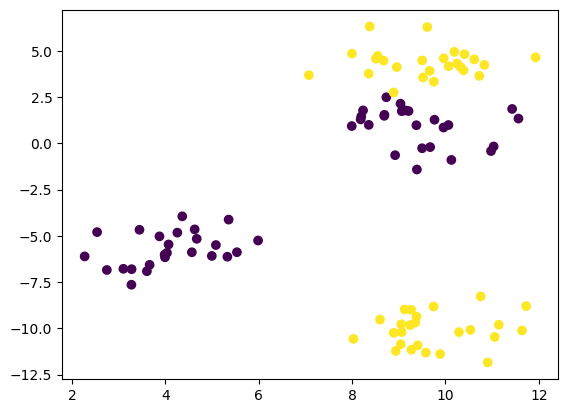

In [1]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import numpy as np

x,y = make_blobs(centers=4, random_state=4)
y = y%2
plt.scatter(x[:,0],x[:,1], c = y)
plt.show()

In [4]:
# x - x 값,y - y값, model - 머신러닝알고리즘
def drawArea(x,y,model):
  # 1. x축과 y축의 범위 를 설정
  x_min,x_max = x[:,0].min()-1, x[:,0].max()+1
  y_min,y_max = x[:,1].min()-1, x[:,1].max()+1

  # 2. 설정된 범위를 가지고 격자모양으로 만든다
  # 2-1. 위에서 만든 범위로 촘촘하게 1차원 리스트로 만든다.
  pos_x = np.arange(x_min,x_max,0.02)
  pos_y = np.arange(y_min,y_max,0.02)

  # 2-2. 위 내용을 가지고 격자모양(grid) 좌표 형태로 변경 한다.
  xx,yy = np.meshgrid(pos_x,pos_y)
  print(f'xx={xx.shape} / yy={yy.shape}')

  # [x,y] 형태의 배열로 변경
  # xx, yy 는 2차원 배열이므로 ravel() 을 통해 1차원 배열로 만들어 줘야 한다.
  print(f'xx.ravel():{xx.ravel()[0]}')
  print(f'yy.ravel():{yy.ravel()[0]}')
  val = np.c_[xx.ravel(), yy.ravel()]
  print(f'val : {val[0]}')

  z = model.predict(val)# [-1,1]
  print(f'z : {z}')
  z = z.reshape(xx.shape)
  plt.scatter(x[:,0],x[:,1],c=y)
  plt.contourf(xx,yy,z,cmap='jet', alpha=0.5)
  plt.show()
# drawArea(x,y,None)

xx=(1009, 583) / yy=(1009, 583)
xx.ravel():1.2716116030870745
yy.ravel():-12.847147972310498
val : [  1.2716116  -12.84714797]
z : [0 0 0 ... 1 1 1]


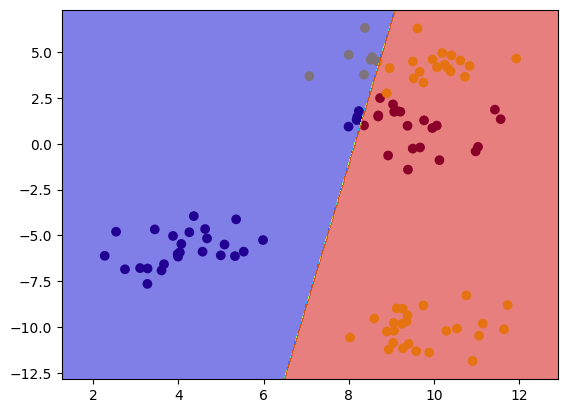

In [6]:
import sklearn.svm as svm

# 서포트 벡터머신 - XOR 문제에서 두개로 분할만 가능
model = svm.LinearSVC(C=0.1,dual=False).fit(x,y)
drawArea(x,y,model)

val : [[  1.2716116  -12.84714797]
 [  1.2916116  -12.84714797]
 [  1.3116116  -12.84714797]
 ...
 [ 12.8716116    7.31285203]
 [ 12.8916116    7.31285203]
 [ 12.9116116    7.31285203]]
z : [1 1 1 ... 1 1 1]


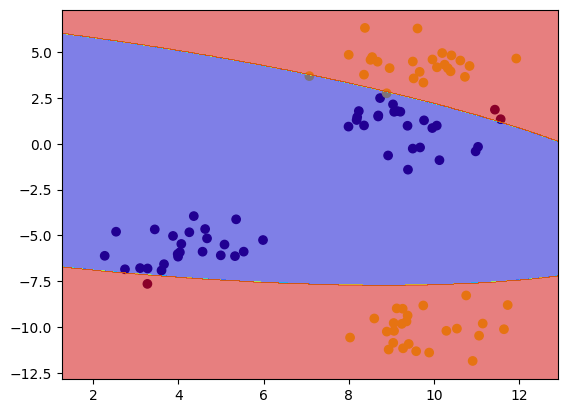

In [ ]:
# 커널사용 - poly(다항커널), rbf(가우시안커널), sigmoid(시그모이드커널)
# degree(default:2) - 다항커널에서만 사용하는 함수 각도
model = svm.SVC(kernel='poly', C=10, degree=2, gamma=20).fit(x,y)
drawArea(x,y,model)

val : [[  1.2716116  -12.84714797]
 [  1.2916116  -12.84714797]
 [  1.3116116  -12.84714797]
 ...
 [ 12.8716116    7.31285203]
 [ 12.8916116    7.31285203]
 [ 12.9116116    7.31285203]]
z : [1 1 1 ... 1 1 1]


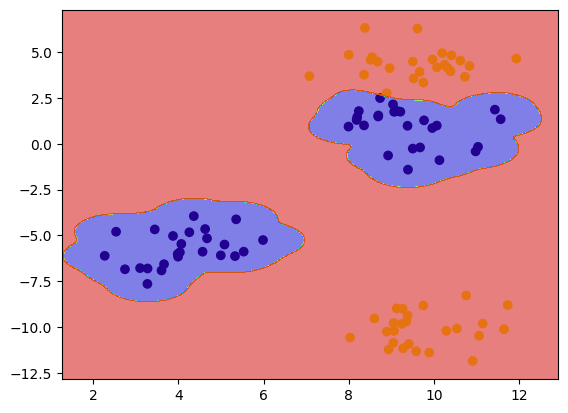

In [ ]:
# C 는 규제 : 0.1~1000(값이 클수록 규제가 강해진다.)
# gamma : 이 값이 클수록 세밀해 진다.(1,10,50,100)
model = svm.SVC(kernel='rbf',C=10, gamma=5).fit(x,y)
drawArea(x,y,model)

val : [[  1.2716116  -12.84714797]
 [  1.2916116  -12.84714797]
 [  1.3116116  -12.84714797]
 ...
 [ 12.8716116    7.31285203]
 [ 12.8916116    7.31285203]
 [ 12.9116116    7.31285203]]
z : [0 0 0 ... 1 1 1]


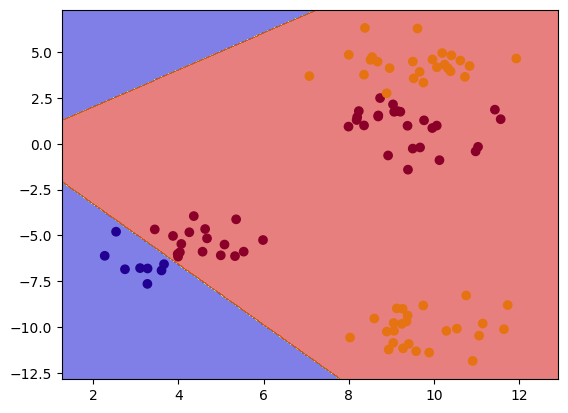

In [ ]:
model = svm.SVC(kernel='sigmoid', C=10, gamma=20).fit(x,y)
drawArea(x,y,model)